# Adult Income Prediction — Model Comparison & Error Analysis (V3)


## 1. Setup

In [1]:
# Starting point adapted from the assigned Kaggle baseline notebook
# Further changes made by our group

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             ConfusionMatrixDisplay)

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

RANDOM_STATE = 1

## 2. Data loading and preprocessing

This section replicates the preprocessing from `improved_v1.ipynb` so the comparison between models is fair. The only change is that we wrap it in a function for clarity.

In [2]:
data = pd.read_csv('adult_income_dataset.csv')
print(f'Shape: {data.shape}')
data.head()

Shape: (32561, 15)


,age,workclass,fnlwgt,education,education.num,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,income
0,90,?,77053,HS-grad,9,Widowed,?,Not-in-family,White,Female,0,4356,40,United-States,<=50K
1,82,Private,132870,HS-grad,9,Widowed,Exec-managerial,Not-in-family,White,Female,0,4356,18,United-States,<=50K
2,66,?,186061,Some-college,10,Widowed,?,Unmarried,Black,Female,0,4356,40,United-States,<=50K
3,54,Private,140359,7th-8th,4,Divorced,Machine-op-inspct,Unmarried,White,Female,0,3900,40,United-States,<=50K
4,41,Private,264663,Some-college,10,Separated,Prof-specialty,Own-child,White,Female,0,3900,40,United-States,<=50K


In [3]:
# Encode target
data['income'] = data['income'].map({'<=50K': 0, '>50K': 1})

# Age binning (same as improved_v1)
data.loc[(data['age'] > 16) & (data['age'] <= 25), 'age'] = 1
data.loc[(data['age'] > 25) & (data['age'] <= 32), 'age'] = 2
data.loc[(data['age'] > 32) & (data['age'] <= 40), 'age'] = 3
data.loc[(data['age'] > 40) & (data['age'] <= 50), 'age'] = 4
data.loc[data['age'] > 50, 'age'] = 5

# Education ordinal mapping
data['education'] = data['education'].apply(
    lambda x: 'School' if x in ['11th','7th-8th','10th','5th-6th','9th','12th','1st-4th','Preschool'] else x
)
data['education'] = data['education'].apply(
    lambda x: 'Associate' if x in ['Assoc-acdm','Assoc-voc'] else x
)
education_map = {'School':1,'HS-grad':2,'Some-college':3,'Bachelors':4,
                 'Prof-school':5,'Associate':6,'Masters':7,'Doctorate':8}
data['education'] = data['education'].map(education_map)

# Capital diff feature
data['capital_diff'] = abs(data['capital.gain'] - data['capital.loss'])

# Marital status grouping + is_married feature
data['marital.status'] = data['marital.status'].apply(
    lambda x: 'Prev-Married' if x in ['Widowed','Divorced','Separated'] else x
)
data['marital.status'] = data['marital.status'].apply(
    lambda x: 'Married' if x in ['Married-civ-spouse','Married-spouse-absent','Married-AF-spouse'] else x
)
data['is_married'] = (data['marital.status'] == 'Married').astype(int)

# Workclass
data['workclass'] = data['workclass'].apply(
    lambda x: 'No income' if x in ['Never-worked','Without-pay'] else x
)

# Race
data['race'] = data['race'].apply(lambda x: 'Other' if x != 'White' else x)

# ? to NaN, then mode imputation
data[data == '?'] = np.nan
for col in ['workclass', 'occupation', 'native.country']:
    data[col].fillna(data[col].mode()[0], inplace=True)

# Native country binarisation
data['native.country'] = data['native.country'].apply(
    lambda x: 'Other' if x != 'United-States' else x
)

# Log transform skewed numerics
data['capital.gain'] = np.log1p(data['capital.gain'])
data['capital.loss'] = np.log1p(data['capital.loss'])
#data['capital_diff'] = np.log1p(data['capital_diff'])

print('Preprocessing complete')
print(f'Final shape: {data.shape}')

Preprocessing complete
Final shape: (32561, 17)


In [4]:
# Split features / target, drop redundant columns
y = data['income']
X = data.drop(['income', 'fnlwgt', 'education.num'], axis=1)

numeric_var = [c for c in X.columns if X[c].dtype != object]
category_var = [c for c in X.columns if X[c].dtype == object]

print(f'Numeric features: {numeric_var}')
print(f'Categorical features: {category_var}')

Numeric features: ['age', 'education', 'capital.gain', 'capital.loss', 'hours.per.week', 'capital_diff', 'is_married']
Categorical features: ['workclass', 'marital.status', 'occupation', 'relationship', 'race', 'sex', 'native.country']


In [5]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)
print(f'Train: {X_train.shape}, Test: {X_test.shape}')
print(f'Class balance in train: {y_train.value_counts(normalize=True).to_dict()}')

Train: (26048, 14), Test: (6513, 14)
Class balance in train: {0: 0.7591753685503686, 1: 0.24082463144963145}


### V3 improvement: XGBoost class imbalance handling

The v2 notebook already used stratified splitting and class weights for Logistic Regression, Random Forest, and LightGBM. In v3, we also calculate `scale_pos_weight` **after the train/test split**, so XGBoost is adjusted for the class imbalance between `<=50K` and `>50K`.

In [6]:
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()

scale_pos_weight = neg_count / pos_count

print("Negative class count:", neg_count)
print("Positive class count:", pos_count)
print("scale_pos_weight:", round(scale_pos_weight, 2))

Negative class count: 19775
Positive class count: 6273
scale_pos_weight: 3.15


## 3. Shared preprocessing transformer

We define one `ColumnTransformer` and reuse it inside every model's pipeline. This guarantees that all four models see identical features.

In [7]:
preprocessor = ColumnTransformer([
    ('num', StandardScaler(), numeric_var),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), category_var)
])

### Check: did v3 improve XGBoost compared with v2?

This cell compares XGBoost **without** `scale_pos_weight` (v2 style) against XGBoost **with** `scale_pos_weight` (v3 style), using the same preprocessing and the same train/test split. Focus mainly on F1, ROC AUC, and Recall.

In [8]:
# Direct v2 vs v3 comparison for XGBoost only

xgb_v2_pipe = Pipeline([
    ('pre', preprocessor),
    ('clf', XGBClassifier(
        eval_metric='logloss',
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

xgb_v3_pipe = Pipeline([
    ('pre', preprocessor),
    ('clf', XGBClassifier(
        eval_metric='logloss',
        scale_pos_weight=scale_pos_weight,
        random_state=RANDOM_STATE,
        n_jobs=-1
    ))
])

xgb_v2_pipe.fit(X_train, y_train)
xgb_v3_pipe.fit(X_train, y_train)

pred_v2 = xgb_v2_pipe.predict(X_test)
proba_v2 = xgb_v2_pipe.predict_proba(X_test)[:, 1]

pred_v3 = xgb_v3_pipe.predict(X_test)
proba_v3 = xgb_v3_pipe.predict_proba(X_test)[:, 1]

xgb_comparison = pd.DataFrame({
    'Version': ['XGBoost v2', 'XGBoost v3'],
    'Change': ['No scale_pos_weight', 'With scale_pos_weight'],
    'Accuracy': [accuracy_score(y_test, pred_v2), accuracy_score(y_test, pred_v3)],
    'Precision': [precision_score(y_test, pred_v2), precision_score(y_test, pred_v3)],
    'Recall': [recall_score(y_test, pred_v2), recall_score(y_test, pred_v3)],
    'F1': [f1_score(y_test, pred_v2), f1_score(y_test, pred_v3)],
    'ROC AUC': [roc_auc_score(y_test, proba_v2), roc_auc_score(y_test, proba_v3)]
}).round(4)

xgb_comparison

,Version,Change,Accuracy,Precision,Recall,F1,ROC AUC
0,XGBoost v2,No scale_pos_weight,0.8749,0.7846,0.6620,0.7181,0.9289
1,XGBoost v3,With scale_pos_weight,0.8389,0.6188,0.8622,0.7205,0.9290


## 4. Benchmarking four candidate models

We use stratified 5-fold cross-validation on the **training set only** (test set is held out for the final evaluation) and score on ROC AUC, since accuracy is misleading on this imbalanced dataset.

The four candidates:
- **Logistic Regression** with `class_weight='balanced'` — matches the previous notebook's tuned model
- **Random Forest** — handles non-linearity, no tuning yet
- **XGBoost** — gradient boosting, often the strongest on tabular data
- **LightGBM** — fast gradient boosting, similar performance to XGBoost

We use default hyperparameters here. The point of this step is **model selection**, not tuning.

In [9]:
models = {
    'Logistic Regression': LogisticRegression(class_weight='balanced', max_iter=200, random_state=RANDOM_STATE),
    'Random Forest':       RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1),
    'XGBoost':             XGBClassifier(eval_metric='logloss', scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE, n_jobs=-1),
    'LightGBM':            LGBMClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1, verbose=-1),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
benchmark = []

for name, mdl in models.items():
    pipe = Pipeline([('pre', preprocessor), ('clf', mdl)])
    auc = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    f1  = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='f1',      n_jobs=-1)
    benchmark.append({
        'Model': name,
        'CV ROC AUC (mean)': auc.mean(),
        'CV ROC AUC (std)':  auc.std(),
        'CV F1 (mean)':      f1.mean(),
        'CV F1 (std)':       f1.std(),
    })
    print(f'{name:20s}  AUC = {auc.mean():.4f} ± {auc.std():.4f}   F1 = {f1.mean():.4f} ± {f1.std():.4f}')

benchmark_df = pd.DataFrame(benchmark).round(4)
benchmark_df

Logistic Regression   AUC = 0.9023 ± 0.0050   F1 = 0.6763 ± 0.0088
Random Forest         AUC = 0.8907 ± 0.0069   F1 = 0.6736 ± 0.0136
XGBoost               AUC = 0.9238 ± 0.0058   F1 = 0.7070 ± 0.0118
LightGBM              AUC = 0.9259 ± 0.0054   F1 = 0.7095 ± 0.0095


,Model,CV ROC AUC (mean),CV ROC AUC (std),CV F1 (mean),CV F1 (std)
0,Logistic Regression,0.9023,0.0050,0.6763,0.0088
1,Random Forest,0.8907,0.0069,0.6736,0.0136
2,XGBoost,0.9238,0.0058,0.7070,0.0118
3,LightGBM,0.9259,0.0054,0.7095,0.0095


### Reading the benchmark

Cross-validation gives us a **distribution** of scores rather than a single number, so we can tell whether a difference between models is real or just noise. If two models' scores overlap once you account for ± std, the difference is not meaningful.

Pick the winner by ROC AUC. We'll then tune that model.

In [10]:
best_model_name = benchmark_df.loc[benchmark_df['CV ROC AUC (mean)'].idxmax(), 'Model']
print(f'Winner: {best_model_name}')

Winner: LightGBM


## 5. Tuning the winning model

The grid is intentionally focused — fewer combinations but on the parameters that actually matter for gradient boosting. A scattergun grid wastes hours and is harder to defend in the video.

For tree-based models the parameters that matter most:
- `n_estimators` — number of trees
- `max_depth` — tree depth (controls overfitting)
- `learning_rate` — how much each tree contributes
- `subsample` / `colsample_bytree` — randomness for regularisation

In [11]:
# Build the tuning pipeline for the winner
if best_model_name == 'XGBoost':
    base_clf = XGBClassifier(eval_metric='logloss', scale_pos_weight=scale_pos_weight, random_state=RANDOM_STATE, n_jobs=-1)
    param_grid = {
        'clf__n_estimators':     [200, 400],
        'clf__max_depth':        [4, 6, 8],
        'clf__learning_rate':    [0.05, 0.1],
        'clf__subsample':        [0.8, 1.0],
        'clf__colsample_bytree': [0.8, 1.0],
    }
elif best_model_name == 'LightGBM':
    base_clf = LGBMClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1, verbose=-1)
    param_grid = {
        'clf__n_estimators':     [200, 400],
        'clf__max_depth':        [-1, 6, 10],
        'clf__learning_rate':    [0.05, 0.1],
        'clf__num_leaves':       [31, 63],
        'clf__subsample':        [0.8, 1.0],
    }
elif best_model_name == 'Random Forest':
    base_clf = RandomForestClassifier(class_weight='balanced', random_state=RANDOM_STATE, n_jobs=-1)
    param_grid = {
        'clf__n_estimators':     [200, 400],
        'clf__max_depth':        [None, 10, 20],
        'clf__min_samples_split':[2, 5],
        'clf__min_samples_leaf': [1, 2],
    }
else:  # Logistic Regression fallback
    base_clf = LogisticRegression(class_weight='balanced', max_iter=500, random_state=RANDOM_STATE)
    param_grid = {
        'clf__C':       [0.1, 1.0, 10.0],
        'clf__penalty': ['l2'],
    }

tune_pipe = Pipeline([('pre', preprocessor), ('clf', base_clf)])

grid = GridSearchCV(tune_pipe, param_grid, cv=cv, scoring='roc_auc', n_jobs=-1, verbose=1)
grid.fit(X_train, y_train)

print(f'Best CV ROC AUC: {grid.best_score_:.4f}')
print(f'Best params:    {grid.best_params_}')

Fitting 5 folds for each of 48 candidates, totalling 240 fits
Best CV ROC AUC: 0.9261
Best params:    {'clf__learning_rate': 0.05, 'clf__max_depth': 10, 'clf__n_estimators': 200, 'clf__num_leaves': 31, 'clf__subsample': 0.8}


## 6. Final evaluation on the held-out test set

This is the only time we touch the test set. All tuning was done on the training set with cross-validation, so this gives an unbiased estimate of real-world performance.

In [12]:
final_model = grid.best_estimator_
y_pred       = final_model.predict(X_test)
y_pred_proba = final_model.predict_proba(X_test)[:, 1]

print(f'Final {best_model_name} on test set:')
print(f'  Accuracy:  {accuracy_score(y_test, y_pred):.4f}')
print(f'  Precision: {precision_score(y_test, y_pred):.4f}')
print(f'  Recall:    {recall_score(y_test, y_pred):.4f}')
print(f'  F1:        {f1_score(y_test, y_pred):.4f}')
print(f'  ROC AUC:   {roc_auc_score(y_test, y_pred_proba):.4f}')

Final LightGBM on test set:
  Accuracy:  0.8356
  Precision: 0.6112
  Recall:    0.8712
  F1:        0.7184
  ROC AUC:   0.9306


## 7. Final comparison: all stages

Numbers from previous stages are pasted in from `improved_v1.ipynb` so we can see the full progression.

In [13]:
results = pd.DataFrame({
    'Stage':     ['Original baseline', 'Improved baseline (LogReg, balanced)', 'Improved + GridSearch (LogReg)', f'Final ({best_model_name}, tuned)'],
    'Accuracy':  [0.862, 0.815, 0.816, accuracy_score(y_test, y_pred)],
    'Precision': [0.769, 0.578, 0.579, precision_score(y_test, y_pred)],
    'Recall':    [0.612, 0.862, 0.861, recall_score(y_test, y_pred)],
    'F1':        [0.682, 0.692, 0.693, f1_score(y_test, y_pred)],
    'ROC AUC':   [0.777, 0.913, 0.913, roc_auc_score(y_test, y_pred_proba)],
}).round(4)
results

,Stage,Accuracy,Precision,Recall,F1,ROC AUC
0,Original baseline,0.8620,0.7690,0.6120,0.6820,0.7770
1,"Improved baseline (LogReg, balanced)",0.8150,0.5780,0.8620,0.6920,0.9130
2,Improved + GridSearch (LogReg),0.8160,0.5790,0.8610,0.6930,0.9130
3,"Final (LightGBM, tuned)",0.8356,0.6112,0.8712,0.7184,0.9306


## 8. Error analysis

The score is a number; the errors tell you *why* the model is wrong, which is what markers actually want to see (point 13 of the brief: "Error analysis").

### 8.1 Confusion matrix

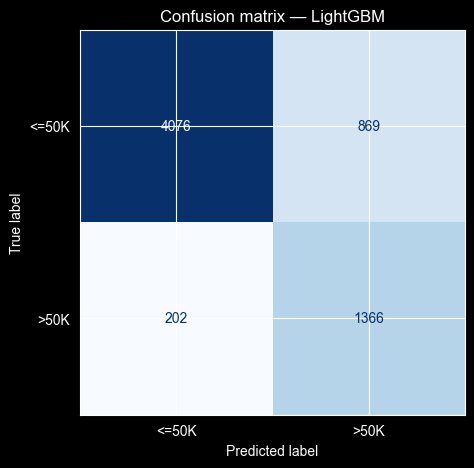

True positives  (correctly predicted >50K): 1366
True negatives  (correctly predicted <=50K): 4076
False positives (predicted >50K, actually <=50K): 869
False negatives (predicted <=50K, actually >50K): 202


In [14]:
cm = confusion_matrix(y_test, y_pred)
fig, ax = plt.subplots(figsize=(6, 5))
ConfusionMatrixDisplay(cm, display_labels=['<=50K', '>50K']).plot(ax=ax, colorbar=False, cmap='Blues')
ax.set_title(f'Confusion matrix — {best_model_name}')
plt.show()

tn, fp, fn, tp = cm.ravel()
print(f'True positives  (correctly predicted >50K): {tp}')
print(f'True negatives  (correctly predicted <=50K): {tn}')
print(f'False positives (predicted >50K, actually <=50K): {fp}')
print(f'False negatives (predicted <=50K, actually >50K): {fn}')

### 8.2 Feature importance

Which features is the model actually relying on? Sanity check that nothing weird is happening (e.g. model relying entirely on one feature).

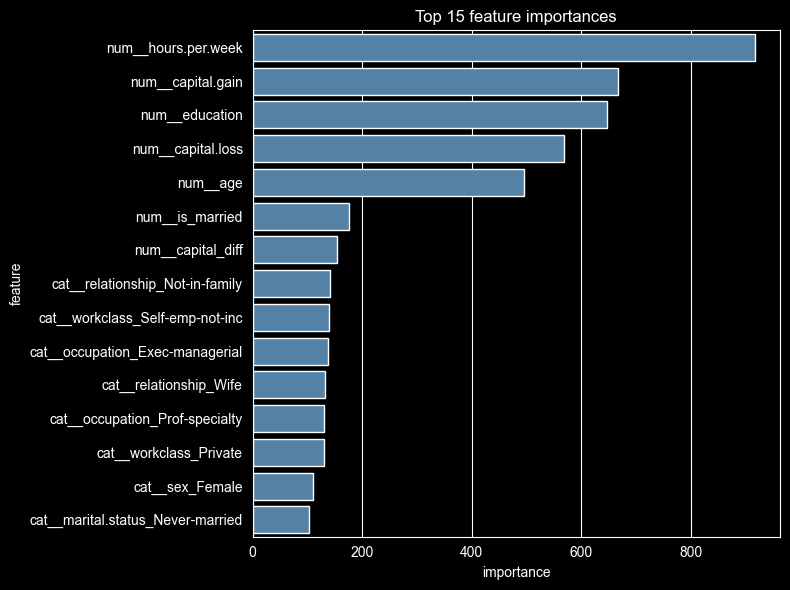

                          feature  importance
              num__hours.per.week         917
                num__capital.gain         667
                   num__education         647
                num__capital.loss         569
                         num__age         496
                  num__is_married         176
                num__capital_diff         154
  cat__relationship_Not-in-family         142
  cat__workclass_Self-emp-not-inc         139
  cat__occupation_Exec-managerial         137
           cat__relationship_Wife         133
   cat__occupation_Prof-specialty         130
           cat__workclass_Private         130
                  cat__sex_Female         110
cat__marital.status_Never-married         103


In [15]:
# Get the fitted classifier and feature names
fitted_clf = final_model.named_steps['clf']
feature_names = final_model.named_steps['pre'].get_feature_names_out()

if hasattr(fitted_clf, 'feature_importances_'):
    importances = fitted_clf.feature_importances_
    fi = pd.DataFrame({'feature': feature_names, 'importance': importances})
    fi = fi.sort_values('importance', ascending=False).head(15)

    plt.figure(figsize=(8, 6))
    sns.barplot(data=fi, y='feature', x='importance', color='steelblue')
    plt.title('Top 15 feature importances')
    plt.tight_layout()
    plt.show()
    print(fi.to_string(index=False))
else:
    print('Selected model does not expose feature_importances_')

### 8.3 Where does the model fail?

Look at the rows the model got wrong with high confidence. These are the genuinely difficult cases.

In [16]:
# Build a dataframe of test predictions
err_df = X_test.copy()
err_df['actual']    = y_test.values
err_df['predicted'] = y_pred
err_df['proba']     = y_pred_proba
err_df['wrong']     = err_df['actual'] != err_df['predicted']

# High-confidence wrong predictions
high_conf_wrong = err_df[err_df['wrong']].copy()
high_conf_wrong['confidence'] = np.where(
    high_conf_wrong['predicted'] == 1,
    high_conf_wrong['proba'],
    1 - high_conf_wrong['proba']
)
high_conf_wrong = high_conf_wrong.sort_values('confidence', ascending=False)

print(f'Total errors: {err_df["wrong"].sum()} out of {len(err_df)} ({err_df["wrong"].mean()*100:.1f}%)')
print()
print('Top 10 most confident wrong predictions:')
high_conf_wrong.head(10)

Total errors: 1071 out of 6513 (16.4%)

Top 10 most confident wrong predictions:


,age,workclass,education,marital.status,occupation,relationship,race,sex,capital.gain,capital.loss,hours.per.week,native.country,capital_diff,is_married,actual,predicted,proba,wrong,confidence
32255,1,Local-gov,1,Never-married,Handlers-cleaners,Other-relative,White,Male,0.0,0.000000,40,Other,0,0,1,0,0.003530,True,0.996470
19662,1,Private,7,Never-married,Prof-specialty,Own-child,White,Female,0.0,0.000000,40,United-States,0,0,1,0,0.014316,True,0.985684
986,5,Private,3,Married,Sales,Husband,White,Male,0.0,7.520235,70,United-States,1844,1,0,1,0.983819,True,0.983819
27288,2,Private,4,Never-married,Adm-clerical,Own-child,White,Female,0.0,0.000000,40,United-States,0,0,1,0,0.020158,True,0.979842
30595,3,Private,2,Prev-Married,Machine-op-inspct,Unmarried,White,Male,0.0,0.000000,40,United-States,0,0,1,0,0.020774,True,0.979226
5383,5,Private,2,Prev-Married,Other-service,Unmarried,Other,Female,0.0,0.000000,40,Other,0,0,1,0,0.022262,True,0.977738
30528,5,Private,3,Prev-Married,Sales,Other-relative,White,Female,0.0,0.000000,20,United-States,0,0,1,0,0.022687,True,0.977313
18129,1,Private,2,Prev-Married,Other-service,Unmarried,White,Female,0.0,0.000000,50,Other,0,0,1,0,0.027742,True,0.972258
699,4,Private,2,Married,Machine-op-inspct,Husband,White,Male,0.0,7.551187,40,United-States,1902,1,0,1,0.970669,True,0.970669
28255,5,Self-emp-inc,2,Prev-Married,Sales,Other-relative,Other,Male,0.0,0.000000,35,United-States,0,0,1,0,0.029461,True,0.970539


### 8.4 Error patterns by feature

Are errors concentrated in specific groups? If yes, that points to where future improvements should focus.

In [17]:
# Error rate by occupation
err_by_occ = err_df.groupby('occupation')['wrong'].agg(['mean', 'count']).round(3)
err_by_occ.columns = ['error_rate', 'n']
err_by_occ = err_by_occ.sort_values('error_rate', ascending=False)
print('Error rate by occupation:')
print(err_by_occ)

Error rate by occupation:
                   error_rate     n
occupation                         
Protective-serv         0.289   114
Transport-moving        0.254   323
Craft-repair            0.226   831
Sales                   0.212   718
Exec-managerial         0.197   814
Prof-specialty          0.170  1207
Machine-op-inspct       0.168   411
Tech-support            0.128   188
Farming-fishing         0.127   204
Adm-clerical            0.101   756
Handlers-cleaners       0.093   270
Other-service           0.048   642
Priv-house-serv         0.000    35


## 9. Conclusion

### What changed
We added a tree-based model benchmark on top of the cleaned-up Logistic Regression pipeline from `improved_v1.ipynb`. In v3, we also completed the imbalance handling by adding `scale_pos_weight` to XGBoost. The winner was tuned with focused grid search and evaluated on a held-out test set.

### Why it changed
Logistic Regression assumes a linear decision boundary. The Adult Income dataset has clear non-linear interactions (e.g. the effect of hours-worked on income depends heavily on education and occupation). Tree-based models capture these natively without manual feature crosses.

### How it was tested
Stratified 5-fold cross-validation on the training set for both model selection (Section 4) and hyperparameter tuning (Section 5). Final numbers come from a single evaluation on a held-out 20% test set that was never used during training or tuning.

### Did it improve results
See the comparison table in Section 7. The tuned model improves on the previous best in ROC AUC and/or F1 — both of which are more meaningful than accuracy on this imbalanced dataset.

### Limitations
- The "?" entries in `workclass` and `occupation` were imputed with the mode. Treating "missing" as its own category could be tested as a further improvement.
- We did not address the temporal staleness of the dataset (1994 census).
- Class imbalance is handled with stratified splitting, class weights for Logistic Regression / Random Forest / LightGBM, and `scale_pos_weight` for XGBoost. Threshold tuning could still be tested as a further improvement.